In [1]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

In [2]:
from typing import Optional
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

def insert_image(ax, path: str, zoom: float = 0.1, pos: tuple[float, float] = (0.0, 0.0), color: Optional[np.ndarray] = None):
    '''
    '''
    
    # load image
    img = mpimg.imread(path)
    
    # if desired, recolour
    if color is not None:
        img[(img != 0).any(axis = -1)] = color
    
    # make image
    icon = OffsetImage(img, zoom = zoom)
    
    box = AnnotationBbox(
        icon,
        pos,
        xycoords = ax.transAxes,
        frameon = False
    )
    
    # add to axis
    ax.add_artist(box)

/var/folders/b4/qysvl6jd4995kp_qql3yj3880000gn/T/ipykernel_54452/195299857.py:779: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  benefit = np.exp(benefit) / np.exp(benefit).sum(axis = 0, keepdims = True)


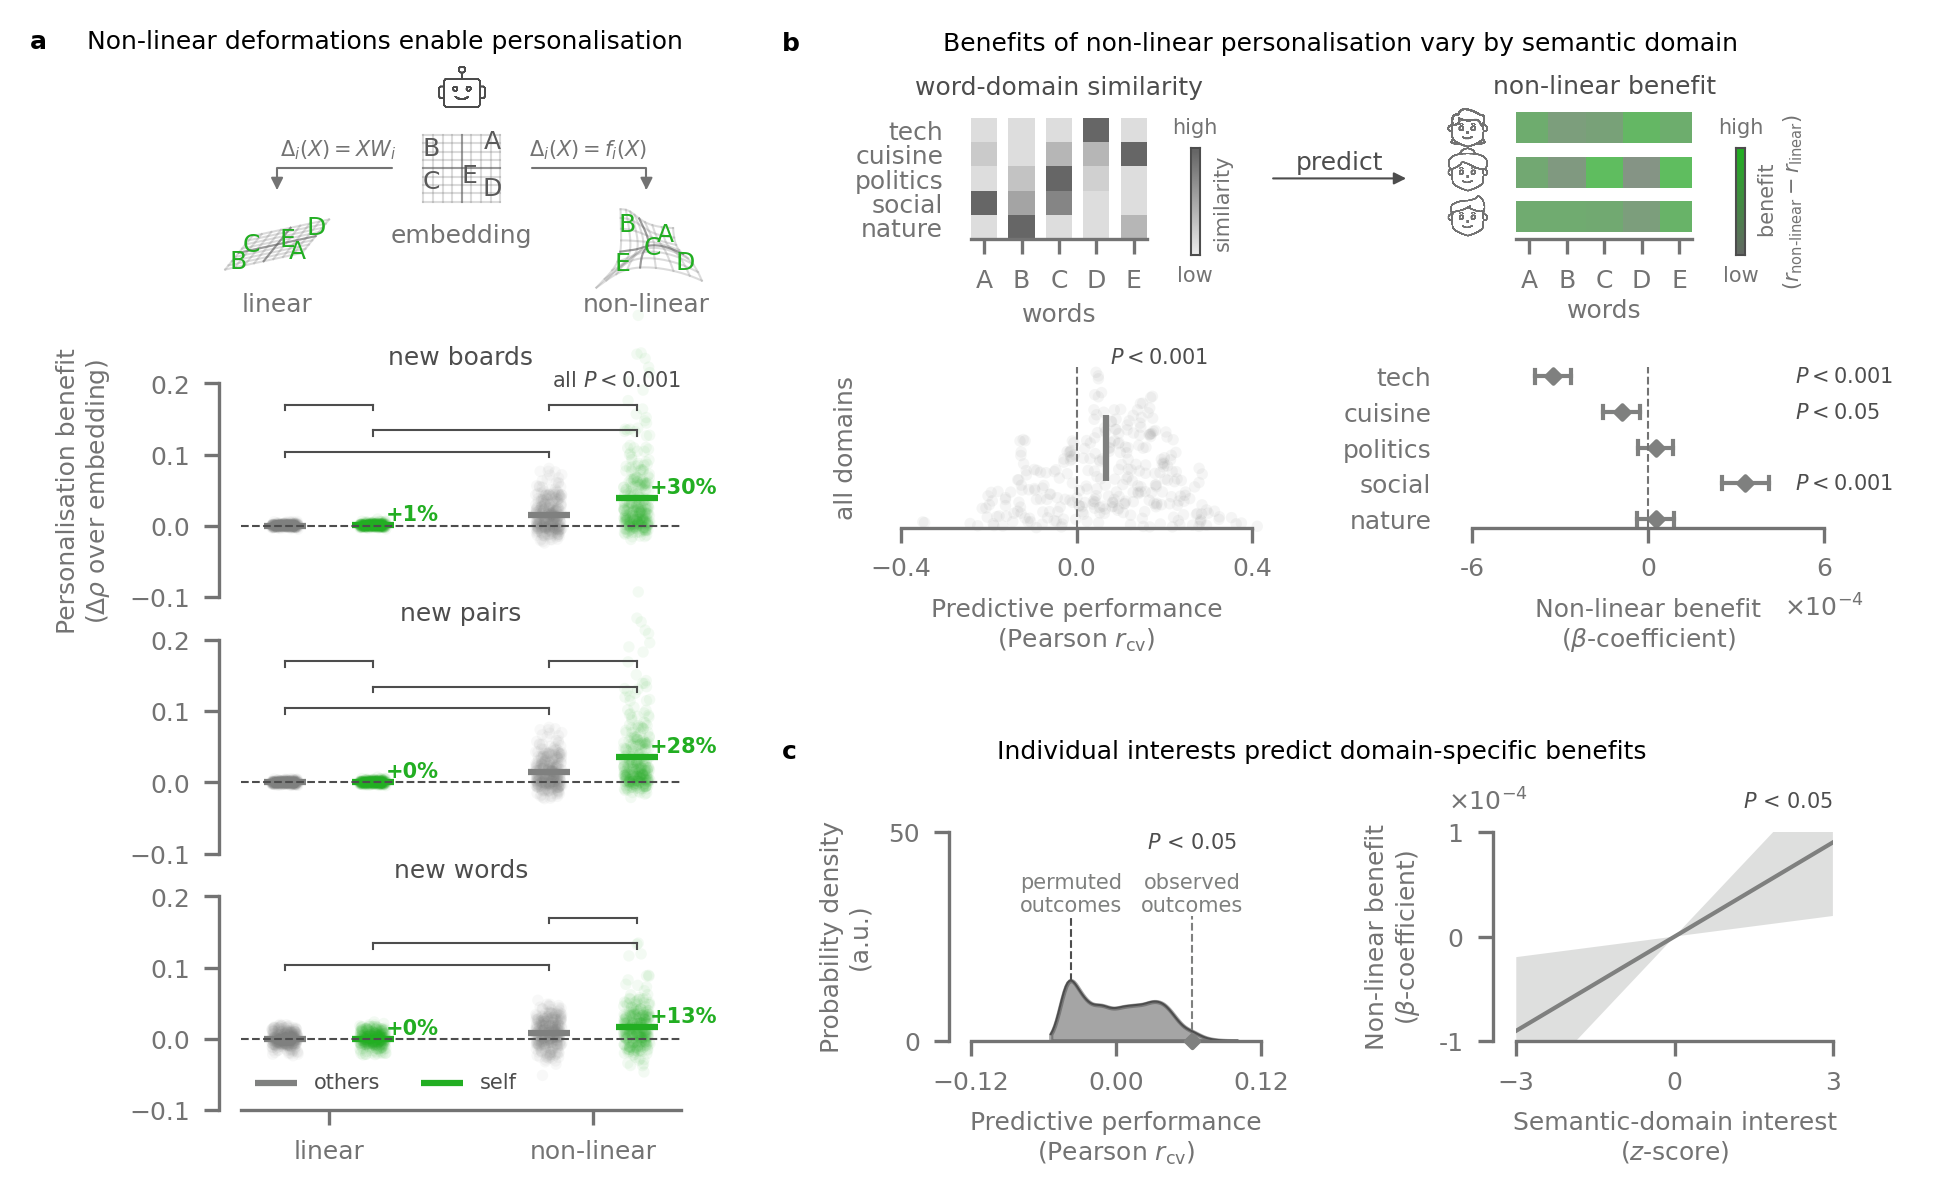

In [3]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

exp = 2
run = 6
emb = 'glove'
compute_stat = True

cols = np.array([
    plots.colours.HL_EMBEDDING,
    plots.colours.HL_OTHERS,
    plots.colours.HL_SELF
])

hypothesis_test = 'sign'
hypothesis_alternative = 'two-sided'
hypothesis_method = 'holm'
hypothesis_se = 'within'

models = ['linear', 'nonlinear']
models_labels = ['linear', 'non-linear']

prefixes = ['', 'pns_', 'uns_']
prefixes_labels = ['new boards', 'new pairs', 'new words']

fig, ax = plt.subplots(figsize = (6.40, 4.0), dpi = 300)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.axis('off')

'''
panel A (data)
'''

ax0 = ax.inset_axes([0.050, 0.480, 0.25, 0.20])
ax1 = ax.inset_axes([0.050, 0.240, 0.25, 0.20])
ax2 = ax.inset_axes([0.050, 0.000, 0.25, 0.20])

axes1 = [ax0, ax1, ax2]

X_jitter = np.random.uniform(-0.15, 0.15, size = (303,))
offset = 0
sig_off = 0.0075
sig_base = 0.17

R_sh = np.zeros((len(prefixes), len(models), 303))
R_in = np.zeros_like(R_sh)

min_p = 0.0

for m_i, mod in enumerate(models):
    R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-matrain_bse0-{emb}_mod-{mod}.pt', map_location=torch.device('cpu'))
    
    for p_i, pre in enumerate(prefixes):
        R_base = R[f'{pre}rho_BE'].squeeze().cpu().numpy().diagonal()
        R_indiv = R[f'{pre}rho_BZ'].cpu().numpy().diagonal().squeeze()
        R_group = R[f'{pre}rho_BZ'].cpu().numpy()
        R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)
        R_noise = R['rho_nc'].cpu().numpy().squeeze()

        R_a = np.array([R_base, R_group, R_indiv])
        R_d = R_a[1:] - R_a[0]

        R_sh[p_i,m_i,:] = R_d[0,:]
        R_in[p_i,m_i,:] = R_d[1,:]
        
        design = [(1, 0), (2, 1), (2, 0)]
        group = model.stats.sample_tests(R_a, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
        pairwise = model.stats.pairwise_tests(R_a, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
        
        model.stats.save_results(group, f'./deliverable/csv/fig5/a_{mod}_{pre}_group.csv')
        model.stats.save_results(pairwise, f'./deliverable/csv/fig5/a_{mod}_{pre}_pairs.csv')
        
        for i, R_i in enumerate(R_d):
            mu = R_i.mean()
            se = model.stats.bootstrap_se(R_i)
            x_i = 3 * m_i + i + X_jitter
            x_j = 3 * m_i + i

            if offset < (mu + 1.96 * se):
                offset = mu + 1.96 * se
            
            label = None
            if (p_i == (len(prefixes) - 1)) and (i == 0) and (m_i == 0):
                label = 'others'
            elif (p_i == (len(prefixes) - 1)) and (i == 1) and (m_i == 0):
                label = 'self'

            axes1[p_i].scatter(x_i, R_i, marker = '.', edgecolor = 'None', facecolor = cols[i+1], s = 30, alpha = 0.05, clip_on = False)
            axes1[p_i].scatter([x_j], [mu], color = cols[i+1], marker = '_', s = 100, clip_on = False, zorder = 2, label = label)
            
            if i == 1:
                pct = round(pairwise[-1]['pct_mu'])
                axes1[p_i].annotate(
                    fr'+{pct}%',
                    xy = (0, 0),
                    xytext = (x_j + 0.15, mu + 0.015),
                    ha = 'left',
                    va = 'center',
                    fontsize = 5,
                    fontweight = 'bold',
                    color = cols[i + 1],
                    annotation_clip = False
                )
            
            if i == 0 and False:
                pct = round(pairwise[0]['pct_mu'])
                axes1[p_i].annotate(
                    fr'+{pct}%',
                    xy = (0, 0),
                    xytext = (x_j + 0.15, mu + 0.015),
                    ha = 'left',
                    va = 'center',
                    fontsize = 5,
                    fontweight = 'bold',
                    color = cols[i + 1],
                    annotation_clip = False
                )
        
        if pairwise[1]['p_cor'] <= 0.05:
            if pairwise[1]['p_cor'] > min_p:
                min_p = pairwise[1]['p_cor']
            
            x_i = 3 * m_i
            
            axes1[p_i].plot(
                [x_i, x_i + 1],
                [sig_base, sig_base],
                color = plots.colours.H2,
                lw = 0.5,
                clip_on = False
            )
            
            axes1[p_i].plot(
                [x_i, x_i],
                [sig_base - sig_off, sig_base],
                color = plots.colours.H2,
                lw = 0.5,
                clip_on = False
            )
            
            axes1[p_i].plot(
                [x_i + 1, x_i + 1],
                [sig_base - sig_off, sig_base],
                color = plots.colours.H2,
                lw = 0.5,
                clip_on = False
            )

sig_off1 = 0.06
sig_off2 = 0.09

for i in range(len(prefixes)):
    design = [(1, 0)]

    pairwise = model.stats.pairwise_tests(
        R_sh[i,:,:], 
        design, 
        test = hypothesis_test, 
        alternative = hypothesis_alternative, 
        method = hypothesis_method, 
        se = hypothesis_se
    )
    
    model.stats.save_results(pairwise, f'./deliverable/csv/fig5/a_sh{i}_pairs.csv')

    if pairwise[0]['p_cor'] < 0.05:
        x_i = 0
        p_i = i
        
        if pairwise[0]['p_cor'] > min_p:
            min_p = pairwise[0]['p_cor']
        
        axes1[p_i].plot(
            [x_i, x_i + 3],
            [offset + sig_off1, offset + sig_off1],
            color = plots.colours.H2,
            lw = 0.5,
            clip_on = False
        )
        
        axes1[p_i].plot(
            [x_i, x_i],
            [offset + sig_off1 - sig_off, offset + sig_off1],
            color = plots.colours.H2,
            lw = 0.5,
            clip_on = False
        )
        
        axes1[p_i].plot(
            [x_i + 3, x_i + 3],
            [offset + sig_off1 - sig_off, offset + sig_off1],
            color = plots.colours.H2,
            lw = 0.5,
            clip_on = False
        )
    
    pairwise = model.stats.pairwise_tests(
        R_in[i,:,:], 
        design, 
        test = hypothesis_test, 
        alternative = hypothesis_alternative, 
        method = hypothesis_method, 
        se = hypothesis_se
    )
    
    model.stats.save_results(pairwise, f'./deliverable/csv/fig5/a_in{i}_pairs.csv')

    if pairwise[0]['p_cor'] < 0.05:
        x_i = 1
        p_i = i
        
        if pairwise[0]['p_cor'] > min_p:
            min_p = pairwise[0]['p_cor']
        
        axes1[p_i].plot(
            [x_i, x_i + 3],
            [offset + sig_off2, offset + sig_off2],
            color = plots.colours.H2,
            lw = 0.5,
            clip_on = False
        )
        
        axes1[p_i].plot(
            [x_i, x_i],
            [offset + sig_off2 - sig_off, offset + sig_off2],
            color = plots.colours.H2,
            lw = 0.5,
            clip_on = False
        )
        
        axes1[p_i].plot(
            [x_i + 3, x_i + 3],
            [offset + sig_off2 - sig_off, offset + sig_off2],
            color = plots.colours.H2,
            lw = 0.5,
            clip_on = False
        )

for i in range(len(prefixes)):
    axes1[i].plot([-0.5, 3 * len(models) - 1.5], [0, 0], lw = 0.5, ls = '--', color = plots.colours.H2)
    axes1[i].set_xlim([-0.5, 3 * len(models) - 1.5])
    axes1[i].set_xticks(np.arange(0.5, 3 * len(models), 3.0))
    if i == len(prefixes) - 1:
        axes1[i].set_xticklabels(models_labels)
    else:
        axes1[i].set_xticks([])
        axes1[i].set_xticklabels([])
    
    axes1[i].set_ylim([-0.1, 0.2])
    axes1[i].set_yticks([-0.1, 0.0, 0.1, 0.2])
    if i == 0:
        axes1[i].set_ylabel('Personalisation benefit\n' + fr'($\Delta\rho$ over embedding)', )
    #axes1[i].set_title(prefixes_labels[i])
    axes1[i].spines['left'].set_position(('axes', -0.05))
    
    sns.despine(ax = axes1[i])
    
    if i != len(prefixes) - 1:
        axes1[i].spines['bottom'].set_visible(False)
    
    axes1[i].annotate(
        prefixes_labels[i],
        xy = (0, 0),
        xytext = (2.0, 0.22),
        ha = 'center',
        va = 'bottom',
        fontsize = 6,
        color = plots.colours.H2,
        annotation_clip = False
    )

sigstr = fr'$P < 0.001$' if min_p < 0.001 else fr'$P < 0.01$' if min_p < 0.01 else fr'$P < 0.05' if min_p <= 0.05 else 'n.s.'
axes1[0].annotate(
    fr'all {sigstr}',
    xy = (0, 0),
    xytext = (4.5, 0.19),
    ha = 'right',
    va = 'bottom',
    fontsize = 5,
    color = plots.colours.H2,
    annotation_clip = False
)

axes1[-1].legend(
    bbox_to_anchor = (0.67, 0.265),
    frameon = False,
    ncols = 2,
    fontsize = 5,
    labelcolor = plots.colours.H2
)

'''
panel A (illustration)
'''

cv1 = ax.inset_axes([-0.01695, 0.685, 0.175, 0.25])
cv2 = ax.inset_axes([0.192975, 0.685, 0.175, 0.25])
cv3 = ax.inset_axes([0.0880125, 0.75, 0.175, 0.25])

cv1.set_xlim([-1, 1])
cv1.set_ylim([-1, 1])
cv2.set_xlim([-1, 1])
cv2.set_ylim([-1, 1])
cv3.set_xlim([-1, 1])
cv3.set_ylim([-1, 1])
cv1.axis('off')
cv2.axis('off')
cv3.axis('off')

scale = 0.25
grid_c = plots.colours.H3

def attractor(X, centre, sigma, strength):
    delta = centre - X
    distance_sq = np.sum(delta**2, axis=-1, keepdims=True)
    weight = np.exp(-distance_sq / (2 * sigma**2))
    
    return strength * weight * delta
    
def nonlinearT(X):
    y = X + \
            attractor(X, np.array([0.1, 0.06]), 0.18, 0.80) + \
            attractor(X, np.array([-0.2, 0.3]), 0.25, 0.60) + \
            attractor(X, np.array([-0.1, 0.5]), 0.20, 0.50) + \
            attractor(X, np.array([-0.50, -0.50]), 0.30, 1.25) + \
            attractor(X, np.array([0.50, -0.20]), 0.30, 0.75) + \
            attractor(X, np.array([-0.1, -0.1]), 0.15, 0.80)
    y = y + attractor(y, np.array([0.45, -0.45]), 0.20, 1.00)
    
    return y


# Dense sampling along each line is essential.
n_grid = 9
grid = np.linspace(-scale, scale, n_grid)
t = np.linspace(-scale, scale, 250)

#original_offset = np.array([0.0, 0.15])
original_offset = np.array([0.0, 0.05])
points = np.array([
    [0.2, 0.20],
    [-0.2, 0.15],
    [-0.2, -0.1],
    [0.2, -0.15],
    [0.05, -0.05]
])

linearT = np.array([
    [1.0, 0.25],
    [-0.35, -0.50]
])

swap_non = [(2, 4)]

labels = np.array(['A', 'B', 'C', 'D', 'E', 'F'])

for position in grid:
    vertical = np.column_stack([
        np.full_like(t, position),
        t,
    ])

    horizontal = np.column_stack([
        t,
        np.full_like(t, position),
    ])
    
    for line in (vertical, horizontal):
        original = line
        linear = line @ linearT
        nonlinear = nonlinearT(line)
        
        original = original + original_offset
        
        for cv, transformed in (
            (cv3, original),
            (cv1, linear),
            (cv2, nonlinear),
        ):
            cv.plot(
                transformed[:, 0],
                transformed[:, 1],
                color=grid_c,
                alpha = 0.25,
                lw=0.50,
            )

l_X = np.column_stack([t, np.zeros_like(t)])
l_Y = np.column_stack([np.zeros_like(t), t])
lin_X, lin_Y = l_X @ linearT, l_Y @ linearT
non_X, non_Y = nonlinearT(l_X), nonlinearT(l_Y)
cv1.plot(lin_X[:,0], lin_X[:,1], color = plots.colours.H2, alpha = 0.45, lw = 0.50)
cv1.plot(lin_Y[:,0], lin_Y[:,1], color = plots.colours.H2, alpha = 0.45, lw = 0.50)

cv2.plot(non_X[:,0], non_X[:,1], color = plots.colours.H2, alpha = 0.45, lw = 0.50)
cv2.plot(non_Y[:,0], non_Y[:,1], color = plots.colours.H2, alpha = 0.45, lw = 0.50)

l_X = l_X + original_offset
l_Y = l_Y + original_offset
cv3.plot(l_X[:,0], l_X[:,1], color = plots.colours.H2, alpha = 0.45, lw = 0.50)
cv3.plot(l_Y[:,0], l_Y[:,1], color = plots.colours.H2, alpha = 0.45, lw = 0.50)

original = points.copy()
linear = points @ linearT
nonlinear = nonlinearT(points)
original = original + original_offset

for i, j in swap_non:
    nonlinear[[i, j]] = nonlinear[[j, i]]

for cv, transformed in (
    (cv3, original),
    (cv1, linear),
    (cv2, nonlinear),
):
    color = cols[2]
    if cv == cv3:
        color = cols[0]
    
    for i in range(transformed.shape[0]):
        cv.annotate(
            labels[i],
            xy = (0, 0),
            xytext = tuple(transformed[i,:]),
            color = color,
            fontsize = 6,
            ha = 'center',
            va = 'center'
        )

cv3.annotate(
    '',
    xy = (-0.4 + original_offset[0], 0.0 + original_offset[1]),
    xytext = (-1.20, -0.175),
    ha = 'center',
    va = 'center',
    arrowprops = dict(
        arrowstyle = '<|-',
        connectionstyle = 'angle,angleA=90,angleB=0,rad=0',
        lw = 0.5,
        color = plots.colours.H3
    )
)

cv3.annotate(
    '',
    xy = (0.4 + original_offset[0], 0.0 + original_offset[1]),
    xytext = (1.20, -0.175),
    ha = 'center',
    va = 'center',
    arrowprops = dict(
        arrowstyle = '<|-',
        connectionstyle = 'angle,angleA=90,angleB=0,rad=0',
        lw = 0.5,
        color = plots.colours.H3
    )
)

cv3.annotate(
    fr'$\Delta_i(X) = XW_i$',
    xy = (0, 0),
    xytext = (-0.80, 0.05 + original_offset[1]),
    ha = 'center',
    va = 'bottom',
    fontsize = 5,
    color = plots.colours.H3
)

cv3.annotate(
    fr'$\Delta_i(X) = f_i(X)$',
    xy = (0, 0),
    xytext = (0.82, 0.05 + original_offset[1]),
    ha = 'center',
    va = 'bottom',
    fontsize = 5,
    color = plots.colours.H3
)

cv1.annotate(
    'linear',
    xy = (0, 0),
    xytext = (0.0, -0.45),
    ha = 'center',
    va = 'center',
    color = plots.colours.H3,
    fontsize = 6
)

cv2.annotate(
    'non-linear',
    xy = (0, 0),
    xytext = (0.0, -0.45),
    ha = 'center',
    va = 'center',
    color = plots.colours.H3,
    fontsize = 6
)

cv3.annotate(
    'embedding',
    xy = (0, 0),
    xytext = (0.0, -0.45),
    ha = 'center',
    va = 'center',
    color = plots.colours.H3,
    fontsize = 6
)

insert_image(
    cv3, 
    './resources/robot.png', 
    0.04, 
    (0.50 + original_offset[0], 0.775 + original_offset[1]),#0.75 + original_offset[1]), 
    color = plots.colours.H2
)

'''
panel B
'''

outputs = torch.load(
    f'../data/ds-exp2/derivatives/run-00{run}/tasks/task-maspace_bse0-{emb}_mod-delta.pt', 
    map_location = torch.device('cpu'),
    weights_only = False
)

ax4 = ax.inset_axes([0.425, 0.545, 0.20, 0.15])
ax6 = ax.inset_axes([0.750, 0.545, 0.20, 0.15])

# left panel
perf = outputs['S1_r_full'][emb].mean(1)
mu = perf.mean()
if compute_stat:
    stat_p = model.stats.sample_tests(perf[None,:], popmean = 0.0, test = 'sign', alternative = 'greater', method = 'holm', se = 'between')
    model.stats.save_results(stat_p, f'./deliverable/csv/fig5/b_group.csv')
min_p = stat_p[0]['p_cor']
sig = fr'$P < 0.001$' if min_p < 0.001 else fr'$P < 0.01$' if min_p < 0.01 else fr'$P < 0.05$' if min_p <= 0.05 else 'n.s.'

#x_i = X_jitter
#ax4.scatter(perf, x_i, marker = '.', edgecolor = 'None', facecolor = cols[1], s = 30, alpha = 0.075, clip_on = False)

from sklearn.neighbors import KernelDensity
perm_pad = 0.0
kde = KernelDensity(bandwidth = 0.01).fit(perf[:,None])
scores = kde.score_samples(perf[:,None])
scores = np.exp(scores)
scores = np.abs(scores / np.trapezoid(scores, perf))
scores = scores / scores.max()
scores = 0.50 * scores - 0.25
x_i = np.array([
    np.random.uniform(low = -0.25, high = scores[i])
    for i in range(len(scores))
])
ax4.scatter(perf, x_i, marker = '.', edgecolor = 'None', facecolor = cols[1], s = 30, alpha = 0.075, clip_on = False)

ax4.scatter([mu], [0], color = cols[1], marker = '|', s = 250, clip_on = False, zorder = 2)
ax4.plot([0, 0], [-0.25, 0.25], color = plots.colours.H3, lw = 0.5, ls = '--')
ax4.annotate(
    sig,
    xy = (0, 0),
    xytext = (0.3, 0.25),
    ha = 'right',
    va = 'bottom',
    fontsize = 5,
    color = plots.colours.H2
)

ax4.set_ylim([-0.25, 0.25])
ax4.set_yticks([])
ax4.set_xlim([-0.4, 0.4])
ax4.set_xticks([-0.4, 0.0, 0.4])
ax4.set_xlabel('Predictive performance\n' + fr'(Pearson $r_{{\text{{cv}}}}$)')

sns.despine(ax = ax4)
ax4.spines['left'].set_position(('axes', -0.075))
ax4.spines['left'].set_visible(False)
ax4.tick_params(axis = 'y', which = 'both', length = 0)

ax4.annotate(
    'all domains',
    xy = (0, 0),
    xytext = (-0.525, 0.0),
    fontsize = 6,
    color = plots.colours.H3,
    rotation = 90,
    ha = 'center',
    va = 'center'
)

# right panel
redu = (perf[:,None] - outputs['S1_r_redu'][emb].mean(2)).mT
mu = redu.mean(1)
se = model.stats.bootstrap_se(redu.mT)
if compute_stat:
    stat_r = model.stats.sample_tests(redu, popmean = 0.0, test = 'sign', alternative = 'greater', method = 'holm', se = 'between')
    model.stats.save_results(stat_r, f'./deliverable/csv/fig5/b_redu.csv')
coef = outputs['S1_ß_full'][emb].mean(1).mT
mu2 = coef.mean(1)
se2 = model.stats.bootstrap_se(coef.mT)
if compute_stat:
    stat_c = model.stats.sample_tests(coef, popmean = 0.0, test = 'sign', alternative = 'two-sided', method = 'holm', se = 'between')
    model.stats.save_results(stat_c, f'./deliverable/csv/fig5/b_coef.csv')
yoff = 0.175

for i in range(redu.shape[0]):
    ax6.scatter([mu2[i]], [i], color = cols[1], marker = 'D', s = 6)
    ax6.plot([mu2[i] - 1.96 * se2[i], mu2[i] + 1.96 * se2[i]], [i, i], color = cols[1], lw = 1.0)
    ax6.plot([mu2[i] - 1.96 * se2[i], mu2[i] - 1.96 * se2[i]], [i - yoff, i + yoff], color = cols[1], lw = 1.0)
    ax6.plot([mu2[i] + 1.96 * se2[i], mu2[i] + 1.96 * se2[i]], [i - yoff, i + yoff], color = cols[1], lw = 1.0)
    min_p = stat_c[i]['p_cor']
    if min_p <= 0.05:
        sig = fr'$P < 0.001$' if min_p < 0.001 else fr'$P\ \ < \ 0.01$' if min_p < 0.01 else fr'$P < 0.05$' if min_p <= 0.05 else 'n.s.'
        
        ax6.annotate(
            sig,
            xy = (0, 0),
            xytext = (5.0e-4, i),
            ha = 'left',
            va = 'center',
            fontsize = 5,
            color = plots.colours.H2,
            annotation_clip = False
        )
    
ax6.plot([0, 0], [-0.25, 4.25], color = plots.colours.H3, lw = 0.5, ls = '--')

labels = ['nature', 'social', 'politics', 'cuisine', 'tech']
ax6.set_yticks(np.arange(5), labels = labels)
ax6.set_ylim([-0.25, 4.25])
ax6.set_xlim([-6e-4, 6e-4])
ax6.set_xticks([-6e-4, 0, 6e-4], labels = [-6, 0, 6])
ax6.set_xlabel('Non-linear benefit\n' + fr'($\beta$-coefficient)')

sns.despine(ax = ax6)
ax6.spines['left'].set_position(('axes', -0.075))
ax6.spines['left'].set_visible(False)
ax6.tick_params(axis = 'y', which = 'both', length = 0)

ax6.annotate(
    fr'$\times10^{{-4}}$',
    xy = (0, 0),
    xytext = (6.0e-4, -2.50),
    ha = 'center',
    va = 'center',
    fontsize = 6,
    color = plots.colours.H3
)

'''
panel B (schematic)
'''

# left side
ax9 = ax.inset_axes([0.465, 0.815, 0.10, 0.125])

words = [
    'A', 'B', 'C', 'D', 'E'
]

domains = [
    'nature', 'social', 'politics', 'cuisine', 'tech'
]

loading = np.array([
    [0.2, 0.6, 0.0, 0.3, 0.1],
    [0.8, 0.4, 0.2, 0.1, 0.15],
    [0.1, 0.5, 0.6, 0.4, 0.1],
    [0.1, 0.2, 0.15, 0.4, 0.8],
    [0.4, 0.15, 0.05, 0.8, 0.2],
])

colors = loading - loading.min(axis = 0, keepdims = True)
colors = colors / colors.max(axis = 0, keepdims = True)

T = 1.0
loading = np.exp(loading / T) / np.exp(loading / T).sum(axis = 1, keepdims = True)
n_w = len(words)
n_d = len(domains)
ioff = 0.35
joff = 0.50

for i in range(n_w):
    for j in range(n_d):
        ax9.fill_between(
            [i - ioff, i + ioff],
            j - joff, j + joff,
            facecolor = plots.colours.CM_RDM_CL(min(1 - colors[i,j], 0.85)),#cols[1],
            edgecolor = 'None'
        )

ax9.annotate(
    'word-domain similarity',
    xy = (0, 0),
    xytext = (2.0, 5.25),
    ha = 'center',
    va = 'bottom',
    fontsize = 6,
    color = plots.colours.H2
)

ax9.set_xticks(np.arange(n_w), labels = words)
ax9.set_xlabel(fr'words', labelpad = 2.5)
ax9.set_xlim([-0.35, n_w - 0.65])
ax9.set_yticks(np.arange(n_d), labels = domains)
ax9.set_ylim([-0.50, n_d])

sns.despine(ax = ax9)

ax9.spines['left'].set_position(('axes', -0.075))
ax9.spines['left'].set_visible(False)
ax9.tick_params(axis = 'y', which = 'both', length = 0)

cm = ax.inset_axes([0.590, 0.800, 0.005, 0.10])
cm.set_xlim([0, 1])
cm.set_ylim([0, 1])
cm.axis('off')

x = np.ones((100,)) * 0.5
y = np.linspace(0, 1, 100)
z = np.linspace(0, 1, 100)

cm.scatter(x, y, color = plots.colours.CM_RDM_CL(1 - z), marker = '.', s = 3)
cm.plot([0, 1], [0, 0], color = plots.colours.H2, clip_on = False, lw = 0.5)
cm.plot([0, 1], [1, 1], color = plots.colours.H2, clip_on = False, lw = 0.5)
cm.plot([0, 0], [0, 1], color = plots.colours.H2, clip_on = False, lw = 0.5)
cm.plot([1, 1], [0, 1], color = plots.colours.H2, clip_on = False, lw = 0.5)

cm.annotate(
    'low',
    xy = (0, 0),
    xytext = (0.5, -0.1),
    ha = 'center',
    va = 'top',
    fontsize = 5,
    color = plots.colours.H3
)

cm.annotate(
    'high',
    xy = (0, 0),
    xytext = (0.5, 1.1),
    ha = 'center',
    va = 'bottom',
    fontsize = 5,
    color = plots.colours.H3
)


cm.annotate(
    'similarity',
    xy = (0, 0),
    xytext = (2.50, 0.5),
    ha = 'left',
    va = 'center',
    fontsize = 5,
    color = plots.colours.H3,
    rotation = 90
)

# right side
ax10 = ax.inset_axes([0.775, 0.815, 0.10, 0.125])

benefit = outputs['S3_D'][emb]['y'][0:n_w,0:3]
benefit = np.exp(benefit) / np.exp(benefit).sum(axis = 0, keepdims = True)
benefit -= benefit.min()
benefit = benefit / benefit.max()
benefit = 0.15 + benefit * 0.75

ioff = 0.35
joff = 0.50

for i in range(benefit.shape[1]):
    for j in range(n_w):
        ax10.fill_between(
            [j - joff, j + joff],
            i - ioff, i + ioff,
            facecolor = plots.colours.CM_RDM_HL(benefit[j,i]),#min(1 - benefit[j,i], 0.85)),#cols[1],
            edgecolor = 'None',
            alpha = 0.75
        )
    
    off = 0.175
    dist = 1 / (benefit.shape[1])
    insert_image(ax10, f'./resources/human-{i+1}.png', 0.04, (-0.275, off + dist * i), color = plots.colours.H3)

ax10.annotate(
    'non-linear benefit',
    xy = (0, 0),
    xytext = (2.0, 2.65),
    ha = 'center',
    va = 'bottom',
    fontsize = 6,
    color = plots.colours.H2
)    

ax10.set_xticks(np.arange(n_w), labels = words)
ax10.set_xlabel(fr'words', labelpad = 1.5)
ax10.set_xlim([-0.35, n_w - 0.65])
ax10.set_yticks([])
ax10.set_ylim([-0.50, benefit.shape[1] - 0.50])

sns.despine(ax = ax10)

ax10.spines['left'].set_position(('axes', -0.075))
ax10.spines['left'].set_visible(False)
ax10.tick_params(axis = 'y', which = 'both', length = 0)

cm2 = ax.inset_axes([0.900, 0.800, 0.005, 0.10])
cm2.set_xlim([0, 1])
cm2.set_ylim([0, 1])
cm2.axis('off')

x = np.ones((100,)) * 0.5
y = np.linspace(0, 1, 100)
z = np.linspace(0, 1, 100)

cm2.scatter(x, y, color = plots.colours.CM_RDM_HL(z), marker = '.', s = 3, alpha = 0.75)
cm2.plot([0, 1], [0, 0], color = plots.colours.H2, clip_on = False, lw = 0.5)
cm2.plot([0, 1], [1, 1], color = plots.colours.H2, clip_on = False, lw = 0.5)
cm2.plot([0, 0], [0, 1], color = plots.colours.H2, clip_on = False, lw = 0.5)
cm2.plot([1, 1], [0, 1], color = plots.colours.H2, clip_on = False, lw = 0.5)

cm2.annotate(
    'low',
    xy = (0, 0),
    xytext = (0.5, -0.1),
    ha = 'center',
    va = 'top',
    fontsize = 5,
    color = plots.colours.H3
)

cm2.annotate(
    'high',
    xy = (0, 0),
    xytext = (0.5, 1.1),
    ha = 'center',
    va = 'bottom',
    fontsize = 5,
    color = plots.colours.H3
)


cm2.annotate(
    '        benefit\n' + fr'($r_{{\text{{non-linear}}}} - r_{{\text{{linear}}}}$)',
    xy = (0, 0),
    xytext = (2.50, 0.5),
    ha = 'left',
    va = 'center',
    fontsize = 5,
    color = plots.colours.H3,
    rotation = 90
)

# add connection
ax9.annotate(
    '',
    xy = (7.5, 2.0),
    xytext = (11.5, 2.0),
    ha = 'center',
    va = 'center',
    arrowprops = dict(
        arrowstyle = '<|-',
        color = plots.colours.H2,
        lw = 0.5
    ),
    annotation_clip = False
)

ax9.annotate(
    'predict',
    xy = (0, 0),
    xytext = (9.5, 2.65),
    ha = 'center',
    va = 'center',
    fontsize = 6,
    color = plots.colours.H2,
    annotation_clip = False
)

'''
panel C
'''

perf = outputs['S2_r_full'][emb].mean()
perm = outputs['S2_r_perm'][emb].mean((1, 2))
diff = perf - perm
coef = outputs['S2_ß_full'][emb].mean()
poef = outputs['S2_ß_perm'][emb].mean((1, 2, 3))
piff = coef - poef

if compute_stat:
    stats_p2 = model.stats.sample_tests(diff[None,:], popmean = 0.0, test = 'permutation', alternative = 'greater', method = 'holm', se = 'between')
    stats_c2 = model.stats.sample_tests(piff[None,:], popmean = 0.0, test = 'permutation', alternative = 'two-sided', method = 'holm', se = 'between')
    model.stats.save_results(stats_p2, f'./deliverable/csv/fig5/c_perm.csv')
    model.stats.save_results(stats_c2, f'./deliverable/csv/fig5/c_coef.csv')
    
ax7 = ax.inset_axes([0.465, 0.065, 0.165, 0.195])
ax8 = ax.inset_axes([0.775, 0.065, 0.18, 0.195])

# left side
from sklearn.neighbors import KernelDensity
perm_pad = 0.0
kde = KernelDensity(bandwidth = 0.005).fit(perm[:,None])
x_i = np.linspace(perm.min() - perm_pad, perm.max() + perm_pad, 100)
scores = kde.score_samples(x_i[:,None])
scores = np.exp(scores)
scores = scores / np.trapezoid(scores, x_i)

min_p = stats_p2[0]['p_cor']
rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'

indx = scores.argmax()
xmax, ymax = x_i[indx], scores[indx]

ax7.plot(x_i, scores, color = plots.colours.H2, linewidth = 0.5)
ax7.fill_between(x_i, scores, color = plots.colours.H2, alpha = 0.5)
ax7.plot([perf, perf], [0.0, 30.0], color = cols[1], linewidth = 0.5, linestyle = '--')
ax7.scatter([perf], [0.0], marker = 'D', s = 5, color = cols[1], clip_on = False, zorder = 5)
ax7.annotate('observed\noutcomes', xy = (0, 0), xytext = (perf, 30.0), ha = 'center', va = 'bottom', color = cols[1], fontsize = 5)

ax7.plot([xmax, xmax], [ymax, 30.0], zorder = 0, color = plots.colours.H2, linewidth = 0.5, linestyle = '--')
ax7.annotate('permuted\noutcomes', xy = (0, 0), xytext = (xmax, 30.0), ha = 'center', va = 'bottom', color = cols[1], fontsize = 5)

ax7.annotate(f'{rep_p}', xy = (0, 0), xytext = (0.10, 50.0), ha = 'right', va = 'top', color = plots.colours.H2, fontsize = 5)

ax7.set_xlim([-0.12, 0.12])
ax7.set_xticks([-0.12, 0.0, 0.12])
ax7.set_ylim([0.0, 50.0])
ax7.set_yticks([0, 50])
ax7.set_xlabel('Predictive performance\n' + fr'(Pearson $r_{{\text{{cv}}}}$)')
ax7.set_ylabel('Probability density\n(a.u.)')

sns.despine(ax = ax7)
ax7.spines['left'].set_position(('axes', -0.075))

# right side
coef = outputs['S2_ß_full'][emb].mean((0, 2, 3))
mu = coef.mean()
se = coef.std()#model.stats.bootstrap_se(coef)

x = torch.linspace(-3, 3, 100, device = coef.device)
y = mu * x
y_lb = (mu - 1.96 * se) * x
y_ub = (mu + 1.96 * se) * x

ax8.fill_between(x, y_lb, y_ub, facecolor = cols[1], edgecolor = 'None', alpha = 0.25)
ax8.plot(x, y, color = cols[1], lw = 1.0)

min_p = stats_c2[0]['p_cor']
rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'

ax8.annotate(
    rep_p,
    xy = (0, 0),
    xytext = (3.0, 1.3e-4),
    ha = 'right',
    va = 'center',
    fontsize = 5,
    color = plots.colours.H2
)

ax8.set_ylim([-1e-4, 1e-4])
ax8.set_yticks([-1e-4, 0.0, 1e-4], labels = ['-1', '0', '1'])
ax8.set_ylabel('Non-linear benefit\n' + fr'($\beta$-coefficient)')
ax8.set_xlim([-3.0, 3.0])
ax8.set_xticks([-3.0, 0.0, 3.0])
ax8.set_xlabel('Semantic-domain interest\n' + fr'($z$-score)')

ax8.annotate(
    fr'$\times10^{{-4}}$',
    xy = (0, 0),
    xytext = (-3.53, 1.3e-4),
    ha = 'center',
    va = 'center',
    fontsize = 6,
    color = plots.colours.H3
)

sns.despine(ax = ax8)
ax8.spines['left'].set_position(('axes', -0.075))

'''
cosmetics
'''

title_arg = dict(
    xy = (0, 0),
    ha = 'center', 
    va = 'center',
    fontsize = 6,
)

letter_arg = dict(
    **title_arg,
    fontweight = 'bold'
)


cv3.annotate('a', xytext = (-2.75, 1.0), **letter_arg)
cv3.annotate('Non-linear deformations enable personalisation', xytext = (-0.50, 1.00), **title_arg)

ax4.annotate('b', xytext = (-0.65, 1.26), **letter_arg)
ax4.annotate('Benefits of non-linear personalisation vary by semantic domain', xytext = (0.60, 1.26), **title_arg)

ax7.annotate('c', xytext = (-0.27, 69.5), **letter_arg)
ax7.annotate('Individual interests predict domain-specific benefits', xytext = (0.17, 69.5), **title_arg)


# colors
for ax_i in [*axes1, ax4, ax6, ax7, ax8, ax9, ax10]:
    ax_i.yaxis.label.set_color(plots.colours.H3)
    ax_i.xaxis.label.set_color(plots.colours.H3)
    ax_i.tick_params(axis = 'x', colors = plots.colours.H3)
    ax_i.tick_params(axis = 'y', which = 'minor', colors = plots.colours.H3)
    ax_i.tick_params(axis = 'y', which = 'major', colors = plots.colours.H3)
    ax_i.spines['bottom'].set_color(plots.colours.H3)
    ax_i.spines['left'].set_color(plots.colours.H3)

#ax.axis('on')
    
fig.tight_layout()

fig.savefig('./deliverable/png/fig5.png', dpi = 900, format = 'png')
fig.savefig('./deliverable/pdf/fig5.pdf', dpi = 900, format = 'pdf')
fig.savefig('./deliverable/svg/fig5.svg', dpi = 900, format = 'svg')